# M03 — Admisión magnética y retención espacial

**Level 2 · Prerrequisitos: notebook de fundamentos; lectura: 25 minutos.**

## Objetivos

Ejecute parser estricto y planificador geométrico sobre el fixture protocolario original versionado de 288 filas. No contiene respuesta magnética medida. Es ejemplo de partición/control de filtración, no de correcciones, gridding, continuación ni inversión.

## Preparación

Use el entorno pipeline Python 3.12 ya revisado. Este notebook no instala nada.

Importe el código del repositorio y confirme su archivo fuente.

In [1]:
import runpy,sys
from pathlib import Path
root=Path.cwd().parents[2];sys.path.insert(0,str(root/'data-pipeline'))
from magnetic_survey_json import parse_request
from magnetic_survey import plan_geometry
support=runpy.run_path(str(root/'tests/data/magnetic_survey_support.py'))
# Verify the actual planner's source location.
print(Path(__import__('magnetic_survey').__file__).name)

magnetic_survey.py


## Datos

Ejecute parser estricto y planificador geométrico sobre el fixture protocolario original versionado de 288 filas. No contiene respuesta magnética medida. Es ejemplo de partición/control de filtración, no de correcciones, gridding, continuación ni inversión.

**Files:** tests/data/magnetic_survey_support.py, tests/fixtures/magnetic_survey/generate.py, docs/methods/magnetic-survey/README.md

## Método

El contrato fija ENU en metros, grupos vuelo/fuente, bloques espaciales deterministas, holdout externo y pliegues con buffer. Filas del mismo grupo/bloque permanecen juntas; rango y cobertura se revisan antes de materializar verosimilitud. Controla filtración espacial, pero no corrige variación diurna, IGRF, altura ni grillas del proveedor.

El fixture entrega coordenadas este/norte/arriba en metros, IDs de grupo de vuelo, ancho de bloque espacial explícito y buffer de 200 m. El planificador une filas que comparten grupo de vuelo o bloque espacial; conexiones transitivas forman unidades indivisibles. Ordena unidades determinísticamente, retiene cerca de una quinta parte para evaluación externa y crea pliegues de desarrollo. En cada pliegue se eliminan filas de ajuste a distancia b o menor de validación o holdout: se conserva i solo si minⱼ∈H ‖xᵢ−xⱼ‖₂>b. Es una regla de control de filtración, no una corrección magnética. La partición espacial train/test de Verde es la referencia relacionada [API](https://www.fatiando.org/verde/latest/api/generated/verde.train_test_split.html).

El planificador también comprueba rango geométrico: para coordenadas horizontales centradas X=[1,e−ē,n−n̄] se exige rango(X)=3, evitando particiones colapsadas a una línea. Verifica soporte de coordenadas, no identificabilidad de propiedades físicas. El fixture tiene doce líneas de vuelo y 288 posiciones, pero respuesta magnética cero. La figura muestra pertenencia exacta de filas al pliegue 1, incluidas exclusiones por buffer. La elegibilidad actual niega explícitamente aceptación online/completa: derechos, linaje, verosimilitud validada y enlace del optimizador siguen sin resolverse.


Ejecute el método del producto sobre el control declarado.

In [2]:
raw=support['encode'](support['request']())
# Validate exact serialized bytes and compute the deterministic geometry seal.
handle=parse_request(raw);plan=plan_geometry(handle)
print({'esquema':handle.metadata()['schema'],'hash_particion':plan['partition']['sha256'],'filas_outer':len(plan['partition']['outer_rows']),'pliegues':len(plan['partition']['folds']),'inversion_ejecutada':False})

{'esquema': 'magnetic-survey-inversion-1', 'hash_particion': '18c36c658217ee39da1c3cdda336389f4b0a0d8115c928b6707a114e1753e12e', 'filas_outer': 4, 'pliegues': 3, 'inversion_ejecutada': False}


La partición espacial bloqueada es preferible a dividir puntos al azar en líneas correlacionadas. Verde documenta partición espacial train/test ([referencia API](https://www.fatiando.org/verde/latest/api/generated/verde.train_test_split.html)); el producto además sella grupos y aplica buffer a filas retenidas. Los módulos actuales ejecutan parser/geometría: no corrección magnética, núcleo ni optimizador.

Use directamente los índices de filas devueltos por el planificador. La figura cartografía el diseño de partición con ejes físicos en metros; sus categorías codifican la política de ajuste/holdout, nunca amplitud magnética.


{'externo': 72, 'ajuste': 144, 'validacion': 72, 'buffer': 0, 'full_method_accepted': False, 'field_source_verified': False, 'geology_truth_known': False, 'online_admitted': False}


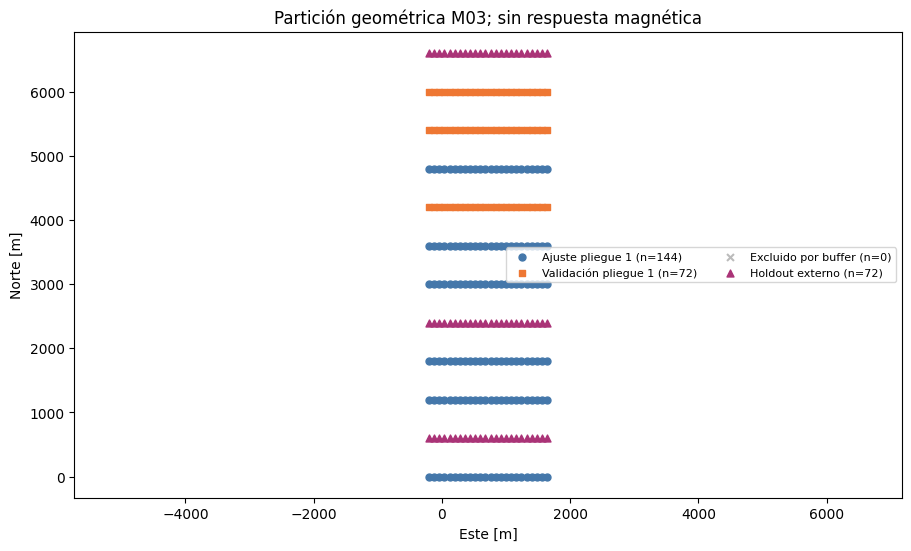

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Graficar índices exactos del planificador sobre geometría local creada; los colores solo codifican partición.
meta=handle.metadata(); xyz=np.asarray(meta['geometry']['receivers_m']['data'],dtype=float).reshape(-1,3)
externo=np.asarray(plan['partition']['outer_rows']['data'],dtype=int); f=plan['partition']['folds'][0]
ajuste=np.asarray(f['fit_rows']['data'],dtype=int); validacion=np.asarray(f['validation_rows']['data'],dtype=int); buffer=np.asarray(f['buffered_rows']['data'],dtype=int)
desarrollo=set(plan['partition']['development_rows']['data'])
assert not (set(externo)&desarrollo) and not (set(ajuste)&set(validacion) or set(ajuste)&set(buffer) or set(validacion)&set(buffer))
fig,ax=plt.subplots(figsize=(9,5.4),constrained_layout=True)
for ids,etiqueta,color,marcador in [(ajuste,'Ajuste pliegue 1','#4477aa','o'),(validacion,'Validación pliegue 1','#ee7733','s'),(buffer,'Excluido por buffer','#bbbbbb','x'),(externo,'Holdout externo','#aa3377','^')]:
 ax.scatter(xyz[ids,0],xyz[ids,1],label=f'{etiqueta} (n={len(ids)})',c=color,marker=marcador,s=25)
ax.set(xlabel='Este [m]',ylabel='Norte [m]',title='Partición geométrica M03; sin respuesta magnética')
ax.set_aspect('equal',adjustable='datalim'); ax.legend(ncol=2,fontsize=8)
print({'externo':len(externo),'ajuste':len(ajuste),'validacion':len(validacion),'buffer':len(buffer),**plan['claims']})
plt.show()


## Resultados

Una ejecución exitosa indica que pasaron esquema y partición, no procesamiento M03, predicción retenida ni aceptación de campo. Si falla, conserve el rechazo; no reduzca buffers ni sintetice mediciones.

## Resumen

La parte implementada es admisión geométrica. QC de líneas/tie, correcciones, gridding, derechos de fuente y observaciones retenidas reales son requisitos separados.




## Referencias

- https://www.fatiando.org/verde/latest/api/generated/verde.train_test_split.html